## Checking shape of files for X and Y

In [21]:
import sys
sys.path.append('/path/to/fmri-language-encoding-models')
sys.path.append('/path/to/fmri-language-encoding-models/code')

import numpy as np
import pickle
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split


Matplotlib is building the font cache; this may take a moment.


In [3]:
# load raw stories
raw_stories = pickle.load(open('/tmp/raw_text.pkl', 'rb'))

print("total stories in raw_stories:", len(raw_stories))
print("story names:", list(raw_stories.keys()))

total stories in raw_stories: 109
story names: ['sweetaspie', 'thatthingonmyarm', 'tildeath', 'indianapolis', 'lawsthatchokecreativity', 'golfclubbing', 'jugglingandjesus', 'shoppinginchina', 'cocoonoflove', 'hangtime', 'beneaththemushroomcloud', 'dialogue4', 'thepostmanalwayscalls', 'stumblinginthedark', 'kiksuya', 'haveyoumethimyet', 'theinterview', 'againstthewind', 'tetris', 'canplanetearthfeedtenbillionpeoplepart2', 'alternateithicatom', 'goldiethegoldfish', 'seedpotatoesofleningrad', 'onapproachtopluto', 'canplanetearthfeedtenbillionpeoplepart1', 'bluehope', 'superheroesjustforeachother', 'howtodraw', 'myfirstdaywiththeyankees', 'thumbsup', 'avatar', 'mayorofthefreaks', 'gangstersandcookies', 'breakingupintheageofgoogle', 'forgettingfear', 'waitingtogo', 'firetestforlove', 'goingthelibertyway', 'thefreedomridersandme', 'exorcism', 'itsabox', 'inamoment', 'afearstrippedbare', 'swimmingwithastronauts', 'ifthishaircouldtalk', 'whenmothersbullyback', 'vixenandtheussr', 'adollshouse',

/tmp/ipykernel_2834715/56715147.py:2: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  raw_stories = pickle.load(open('/tmp/raw_text.pkl', 'rb'))


In [4]:
# look at a story
story_name = list(raw_stories.keys())[0]
story = raw_stories[story_name]

print("story:", story_name)
print("type:", type(story))
print("attributes:", dir(story))
print("first 20 words:", story.data[:20])

story: sweetaspie
type: <class 'ridge_utils.DataSequence.DataSequence'>
attributes: ['__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__format__', '__ge__', '__getattribute__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__str__', '__subclasshook__', '__weakref__', 'chunk_to_data_ind', 'chunkmeans', 'chunks', 'chunksums', 'copy', 'data', 'data_times', 'data_to_chunk_ind', 'from_chunks', 'from_grid', 'mapdata', 'split_inds', 'tr_times']
first 20 words: ['', 'i', 'embarked', 'on', 'a', 'journey', 'toward', 'the', 'sea', 'of', 'matrimony', 'at', 'the', 'perilous', 'age', 'of', 'forty', 'one', 'yeah', "you'd"]


In [5]:
# find valid stories
available_files = set(f.replace('.npy', '') for f in os.listdir('/tmp/subject2'))

valid_stories = [s for s in raw_stories.keys() if s in available_files]

print(f"total raw stories: {len(raw_stories)}")
print(f"available npy files: {len(available_files)}")
print(f"valid stories (intersection): {len(valid_stories)}")
print(f"missing stories: {set(raw_stories.keys()) - available_files}")

total raw stories: 109
available npy files: 101
valid stories (intersection): 101
missing stories: {'dialogue2', 'dialogue4', 'myfirstdaywiththeyankees', 'dialogue3', 'onlyonewaytofindout', 'dialogue6', 'dialogue1', 'dialogue5'}


In [ ]:
# load processed X matrices
X_tr = pickle.load(open('/path/to/home/X_tr_bow.pkl', 'rb'))
X_tst = pickle.load(open('/path/to/home/X_tst_bow.pkl', 'rb'))

print("train stories in X:", list(X_tr.keys()))
print("test stories in X:", list(X_tst.keys()))

#for story, mat in X_tr.items():
    #print(f"  {story}: {mat.shape}")  # expect (T, vocab_size * 4)

In [8]:
# test and train split
invalid = {'dialogue1', 'dialogue2', 'dialogue3', 'dialogue4',
           'dialogue5', 'dialogue6', 'myfirstdaywiththeyankees',
           'onlyonewaytofindout'}

X_tr_clean = {k: v for k, v in X_tr.items() if k not in invalid}
X_tst_clean = {k: v for k, v in X_tst.items() if k not in invalid}

#print("X_tr stories:", len(X_tr_clean))
#print("X_tst stories:", len(X_tst_clean))

train_stories = list(X_tr_clean.keys())
test_stories = list(X_tst_clean.keys())

print("train stories:", len(train_stories))
print(train_stories)
print("\ntest stories:", len(test_stories))
print(test_stories)

train stories: 82
['theadvancedbeginner', 'superheroesjustforeachother', 'seedpotatoesofleningrad', 'mayorofthefreaks', 'adollshouse', 'cautioneating', 'haveyoumethimyet', 'ifthishaircouldtalk', 'myfathershands', 'thecurse', 'hangtime', 'breakingupintheageofgoogle', 'theclosetthatateeverything', 'leavingbaghdad', 'itsabox', 'golfclubbing', 'odetostepfather', 'gpsformylostidentity', 'exorcism', 'waitingtogo', 'theinterview', 'forgettingfear', 'shoppinginchina', 'swimmingwithastronauts', 'singlewomanseekingmanwich', 'comingofageondeathrow', 'howtodraw', 'canplanetearthfeedtenbillionpeoplepart2', 'learninghumanityfromdogs', 'eyespy', 'bluehope', 'cocoonoflove', 'stumblinginthedark', 'listo', 'canplanetearthfeedtenbillionpeoplepart1', 'indianapolis', 'againstthewind', 'thefreedomridersandme', 'wheretheressmoke', 'jugglingandjesus', 'mybackseatviewofagreatromance', 'buck', 'findingmyownrescuer', 'threemonths', 'theshower', 'afatherscover', 'vixenandtheussr', 'becomingindian', 'penpal', 'not

In [9]:
# helper function to load BOLD on demand ───────────────────────────
def load_bold(story, subject='subject2', data_path='/tmp'):
    return np.load(f'{data_path}/{subject}/{story}.npy')

# test it works
# y = load_bold(train_stories[0])
# print(f"loaded {train_stories[0]}: {y.shape}")  # expect (T, num_voxels)

In [10]:
# just load a few stories to verify things work
test_load_stories = train_stories[:3] + test_stories[:1]

bold_subj2 = {}
bold_subj3 = {}

for story in test_load_stories:
    bold_subj2[story] = np.load(f'/tmp/subject2/{story}.npy')
    bold_subj3[story] = np.load(f'/tmp/subject3/{story}.npy')
    print(f"loaded {story}: {bold_subj2[story].shape}")

print("done")

loaded theadvancedbeginner: (318, 94251)
loaded superheroesjustforeachother: (325, 94251)
loaded seedpotatoesofleningrad: (281, 94251)
loaded thesecrettomarriage: (292, 94251)
done


In [7]:
# takes a really long time to run
# load BOLD responses (Y) for both subjects 
# bold_subj2 = {}
# bold_subj3 = {}

# for story in valid_stories:
#     bold_subj2[story] = np.load(f'/tmp/subject2/{story}.npy')
#     bold_subj3[story] = np.load(f'/tmp/subject3/{story}.npy')

# print("loaded subject2:", len(bold_subj2), "stories")
# print("loaded subject3:", len(bold_subj3), "stories")

In [11]:
# double check Y shapes
print("subject 2 shapes:")
for story, mat in bold_subj2.items():
    print(f"  {story}: {mat.shape}")  # expect (T, num_voxels)

print("\nsubject 3 shapes:")
for story, mat in bold_subj3.items():
    print(f"  {story}: {mat.shape}")

subject 2 shapes:
  theadvancedbeginner: (318, 94251)
  superheroesjustforeachother: (325, 94251)
  seedpotatoesofleningrad: (281, 94251)
  thesecrettomarriage: (292, 94251)

subject 3 shapes:
  theadvancedbeginner: (318, 95556)
  superheroesjustforeachother: (325, 95556)
  seedpotatoesofleningrad: (281, 95556)
  thesecrettomarriage: (292, 95556)


train stories in X: ['theadvancedbeginner', 'superheroesjustforeachother', 'seedpotatoesofleningrad', 'mayorofthefreaks', 'adollshouse', 'cautioneating', 'haveyoumethimyet', 'ifthishaircouldtalk', 'myfathershands', 'thecurse', 'hangtime', 'breakingupintheageofgoogle', 'theclosetthatateeverything', 'leavingbaghdad', 'myfirstdaywiththeyankees', 'itsabox', 'golfclubbing', 'odetostepfather', 'gpsformylostidentity', 'exorcism', 'waitingtogo', 'theinterview', 'dialogue6', 'forgettingfear', 'dialogue5', 'shoppinginchina', 'swimmingwithastronauts', 'singlewomanseekingmanwich', 'comingofageondeathrow', 'howtodraw', 'canplanetearthfeedtenbillionpeoplepart2', 'learninghumanityfromdogs', 'eyespy', 'bluehope', 'cocoonoflove', 'dialogue3', 'dialogue2', 'stumblinginthedark', 'listo', 'canplanetearthfeedtenbillionpeoplepart1', 'indianapolis', 'againstthewind', 'thefreedomridersandme', 'wheretheressmoke', 'jugglingandjesus', 'mybackseatviewofagreatromance', 'buck', 'findingmyownrescuer', 'threemonths',

In [12]:
# check X and Y dimensions align ───────────────────────────────────
print("checking alignment (train, subject2):")
for story in train_stories[:5]:  # check first 5 to keep it fast
    x_rows = X_tr_clean[story].shape[0]
    y_rows = load_bold(story, subject='subject2').shape[0]
    status = "OK" if x_rows == y_rows else "MISMATCH"
    print(f"  {story}: X={x_rows} rows, Y={y_rows} rows -- {status}")

print("\nchecking alignment (test, subject2):")
for story in test_stories[:5]:
    x_rows = X_tst_clean[story].shape[0]
    y_rows = load_bold(story, subject='subject2').shape[0]
    status = "OK" if x_rows == y_rows else "MISMATCH"
    print(f"  {story}: X={x_rows} rows, Y={y_rows} rows -- {status}")

checking alignment (train, subject2):
  theadvancedbeginner: X=318 rows, Y=318 rows -- OK
  superheroesjustforeachother: X=325 rows, Y=325 rows -- OK
  seedpotatoesofleningrad: X=281 rows, Y=281 rows -- OK
  mayorofthefreaks: X=475 rows, Y=475 rows -- OK
  adollshouse: X=241 rows, Y=241 rows -- OK

checking alignment (test, subject2):
  thesecrettomarriage: X=292 rows, Y=292 rows -- OK
  beneaththemushroomcloud: X=342 rows, Y=342 rows -- OK
  lawsthatchokecreativity: X=434 rows, Y=434 rows -- OK
  escapingfromadirediagnosis: X=343 rows, Y=343 rows -- OK
  undertheinfluence: X=304 rows, Y=304 rows -- OK


In [13]:
# full checks on one story ────────────────────────────────
story = train_stories[0]
X = X_tr_clean[story]
Y = load_bold(story, subject='subject2')

print(f"story: {story}")
print(f"X shape: {X.shape}")   # expect (T, vocab_size * 4)
print(f"Y shape: {Y.shape}")   # expect (T, num_voxels)
print(f"X mean: {X.mean():.4f}")
print(f"Y mean: {Y.mean():.4f}")
print(f"any NaN in X: {np.isnan(X).any()}")
print(f"any NaN in Y: {np.isnan(Y).any()}")
print(f"num voxels: {Y.shape[1]}")

story: theadvancedbeginner
X shape: (318, 45056)
Y shape: (318, 94251)
X mean: 0.0004
Y mean: -0.0000
any NaN in X: False
any NaN in Y: False
num voxels: 94251


## Ridge Regression Prep

In [14]:
from sklearn.linear_model import RidgeCV
from scipy.stats import pearsonr

### mini test

In [15]:
subject = 'subject2'
n_voxels_test = 1000  # just first 1000 voxels to keep it fast

mini_train = train_stories[:3]
mini_test = test_stories[:1]

# stack mini train
X_mini = np.vstack([X_tr_clean[s] for s in mini_train])
Y_mini = np.vstack([load_bold(s, subject=subject)[:, :n_voxels_test] 
                    for s in mini_train])

print("X_mini shape:", X_mini.shape)
print("Y_mini shape:", Y_mini.shape)

X_mini shape: (924, 45056)
Y_mini shape: (924, 1000)


In [ ]:
alphas = [10, 100, 1000, 10000]
ridge = RidgeCV(alphas=alphas)
ridge.fit(X_mini, Y_mini)

print("best alpha:", ridge.alpha_)
print("fit complete")

In [17]:
# ── evaluate on mini test ─────────────────────────────────────────────────────
def compute_cc_fast(Y_true, Y_pred):
    Y_true_c = Y_true - Y_true.mean(axis=0)
    Y_pred_c = Y_pred - Y_pred.mean(axis=0)
    num = (Y_true_c * Y_pred_c).sum(axis=0)
    denom = np.sqrt((Y_true_c**2).sum(axis=0) * (Y_pred_c**2).sum(axis=0))
    return np.where(denom > 0, num / denom, 0)

story = mini_test[0]
X_tst_s = X_tst_clean[story]
Y_tst_s = load_bold(story, subject=subject)[:, :n_voxels_test]

Y_pred = ridge.predict(X_tst_s)
cc = compute_cc_fast(Y_tst_s, Y_pred)

print(f"mean CC:   {cc.mean():.4f}")
print(f"median CC: {np.median(cc):.4f}")
print(f"top 1% CC: {np.percentile(cc, 99):.4f}")
print(f"top 5% CC: {np.percentile(cc, 95):.4f}")

mean CC:   0.0007
median CC: 0.0007
top 1% CC: 0.1353
top 5% CC: 0.0980


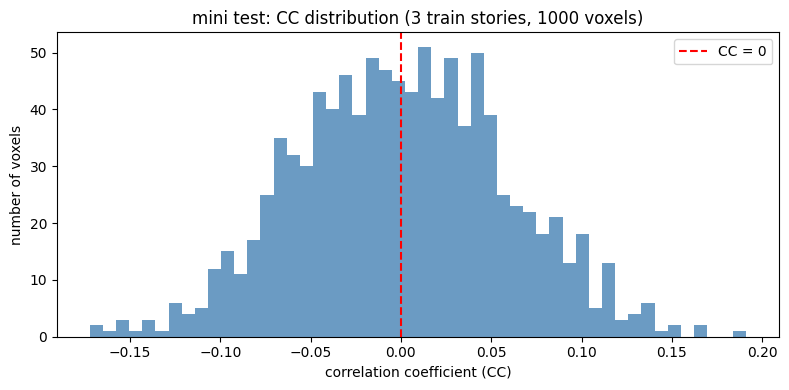

In [22]:
# ── quick plot to confirm it looks reasonable ─────────────────────────────────
plt.figure(figsize=(8, 4))
plt.hist(cc, bins=50, color='steelblue', edgecolor='none', alpha=0.8)
plt.axvline(0, color='red', linestyle='--', label='CC = 0')
plt.xlabel('correlation coefficient (CC)')
plt.ylabel('number of voxels')
plt.title('mini test: CC distribution (3 train stories, 1000 voxels)')
plt.legend()
plt.tight_layout()
plt.show()

meaning of CC values:
- 0: the model has no ability to predict that voxels response
- positive: model predictions are correlated with actual brain responses
- negative: model predictions are inverseley correlated (likely noise?)
- 1: perfect prediction (not achievable, but goal)

This plot shows the distribution is roughly centered around zero meaning that most voxels aren't well predicted. There is a slight right tail/skew with positive CC. This is about expected for Bag of Words and for the fact that we are using a very small training and testing amount for the initial assessment.

### All stories

In [ ]:
# ridge setup: stack train data across stories 
# we fit one ridge model per subject using all train stories concatenated

subject = 'subject2'

# stack all train stories into one big X and Y
# TAKES LONG TIME
X_train_all = np.vstack([X_tr_clean[s] for s in train_stories])
Y_train_all = np.vstack([load_bold(s, subject=subject) for s in train_stories])

print("stacked X_train shape:", X_train_all.shape)  # (total_T, 45056)
print("stacked Y_train shape:", Y_train_all.shape)  # (total_T, 94251)

In [ ]:
# fit ridge model
# RidgeCV does cross validation over alphas automatically
# using a small set of alphas to start — can expand later
alphas = [10, 100, 1000, 10000]

ridge = RidgeCV(alphas=alphas)
ridge.fit(X_train_all, Y_train_all)

print("best alpha:", ridge.alpha_)
print("model fitted successfully")

In [ ]:
# evaluate on test stories
# compute per-voxel pearson correlation (CC) on each test story

def compute_cc(Y_true, Y_pred):
    """compute pearson r per voxel between true and predicted BOLD"""
    n_voxels = Y_true.shape[1]
    cc = np.zeros(n_voxels)
    for v in range(n_voxels):
        cc[v], _ = pearsonr(Y_true[:, v], Y_pred[:, v])
    return cc

# NOTE: this loop will be slow due to 94251 voxels
# we will vectorize it after confirming it works on one story
story = test_stories[0]
X_tst_story = X_tst_clean[story]
Y_tst_story = load_bold(story, subject=subject)

Y_pred = ridge.predict(X_tst_story)
print("Y_pred shape:", Y_pred.shape)
print("Y_tst shape:", Y_tst_story.shape)

In [ ]:
# evaluate on test stories
# compute per-voxel pearson correlation (CC) on each test story

def compute_cc(Y_true, Y_pred):
    """compute pearson r per voxel between true and predicted BOLD"""
    n_voxels = Y_true.shape[1]
    cc = np.zeros(n_voxels)
    for v in range(n_voxels):
        cc[v], _ = pearsonr(Y_true[:, v], Y_pred[:, v])
    return cc

# NOTE: this loop will be slow due to 94251 voxels
# we will vectorize it after confirming it works on one story
story = test_stories[0]
X_tst_story = X_tst_clean[story]
Y_tst_story = load_bold(story, subject=subject)

Y_pred = ridge.predict(X_tst_story)
print("Y_pred shape:", Y_pred.shape)
print("Y_tst shape:", Y_tst_story.shape)

In [ ]:
# faster vectorized CC computation 
# pearsonr in a loop over 94k voxels is too slow
# this computes all voxels at once using matrix operations

def compute_cc_fast(Y_true, Y_pred):
    """vectorized pearson r across all voxels at once"""
    # center each voxel
    Y_true_c = Y_true - Y_true.mean(axis=0)
    Y_pred_c = Y_pred - Y_pred.mean(axis=0)
    
    # compute correlation
    num = (Y_true_c * Y_pred_c).sum(axis=0)
    denom = np.sqrt((Y_true_c**2).sum(axis=0) * (Y_pred_c**2).sum(axis=0))
    
    # avoid division by zero
    cc = np.where(denom > 0, num / denom, 0)
    return cc

cc = compute_cc_fast(Y_tst_story, Y_pred)
print("CC shape:", cc.shape)  # should be (94251,)
print(f"mean CC:         {cc.mean():.4f}")
print(f"median CC:       {np.median(cc):.4f}")
print(f"top 1% CC:       {np.percentile(cc, 99):.4f}")
print(f"top 5% CC:       {np.percentile(cc, 95):.4f}")